# Introduction to numerical algorithms
## Practice class 8 — Random numbers, sampling and shuffling

In this practice you will generate a nonuniform distribution, test a shuffle, and investigate the quality of a random number generator.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# A fixed seed makes an experiment reproducible.
# Create the generator once, then keep using it. Do not reset it inside a loop.
rng = np.random.default_rng(2026)

### A few useful commands

| Command | Meaning |
| --- | --- |
| `rng.random()` | One uniform random number in $[0,1)$ |
| `rng.uniform(low, high)` | One uniform random number between the bounds |
| `rng.integers(low, high)` | One integer from `low` up to, but excluding, `high` |
| `rng.random(n)` | An array of `n` uniform random numbers |
| `plt.hist(values, bins=30, density=True)` | A histogram normalized to unit area |

**Pseudorandom numbers** come from a deterministic algorithm. The seed sets its initial state. The same algorithm and seed reproduce the same sequence; this is useful when debugging.

### Task 1 — Generate a given distribution

Generate samples from the probability density

$$p(x)=\frac{3}{2}\sqrt{1-x},\qquad 0\leq x\leq1,$$

and $p(x)=0$ outside this interval. Use **two different methods** below. The equations are provided; your task is to implement and compare the methods.

#### 1a. Monte Carlo sampling: accept or reject

A Monte Carlo method uses random trials to solve a problem. Here we use **rejection sampling**: imagine throwing points uniformly into a rectangle above the interval $[0,1]$. Keep only the points below the density curve. Where the curve is higher, a larger fraction of points survives, so more accepted $x$ values appear there.

The largest value of the density is $p(0)=3/2$. For each trial:

1. Draw $x$ uniformly from $[0,1)$.
2. Independently draw $y$ uniformly from $[0,3/2)$.
3. If $y<p(x)$, append $x$ to the accepted list.
4. Repeat until you have accepted `n` values. Count **all** proposed points, including rejected ones.

The area below the density is $1$; the rectangle has area $3/2$. The expected acceptance fraction is therefore $2/3$.

Complete `sample_rejection`. Return the accepted values as an array **and** the number of trials.

In [6]:
def density(x):
    # This helper is used only for x in [0, 1].
    return 1.5 * np.sqrt(1 - x)


def sample_rejection(n, rng):
    accepted = []
    trials = 0
    while len(accepted) < n:
        x = rng.random()
        y = rng.uniform(0,3/2)
        trials += 1
        if y < density(x):
            accepted.append(x)
        
    return np.array(accepted), trials

#### 1b. Inverse cumulative distribution

The cumulative distribution $F(x)$ is the probability of obtaining a value at most $x$. For this density,

$$F(x)=\int_0^x p(t)\,dt=1-(1-x)^{3/2}.$$

Draw a uniform number $u\in[0,1)$ and solve $F(x)=u$:

$$x=F^{-1}(u)=1-(1-u)^{2/3}.$$

Complete `sample_inverse`. Generate all `n` uniform values in one call and apply the formula to the array.

In [7]:
def sample_inverse(n, rng):
    # Work Here!
    u = rng.random(n)
    return 1-(1-u)**(2/3)


#### 1c. Check and compare

Run the cell below after implementing both methods. The theoretical mean is

$$\mathbb{E}[X]=\int_0^1 x p(x)\,dx=\frac{2}{5}=0.4.$$

Both histograms should follow the density curve. Their means and the acceptance fraction should be **close** to the predictions, rather than exactly equal. Repeat with `n = 1000` and `n = 100000`.

Acceptance fraction: 0.6688; expected: 0.6667
Rejection mean: 0.3993
Inverse-CDF mean: 0.3952; expected: 0.4000


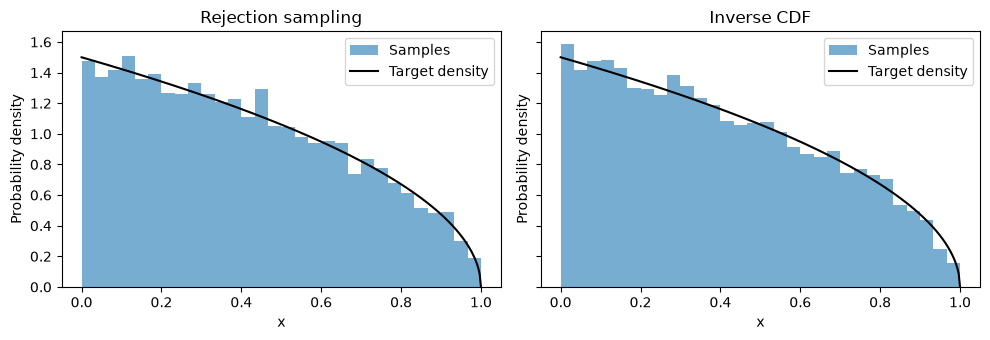

In [8]:
n = 10000
rejection_samples, trials = sample_rejection(n, rng)
inverse_samples = sample_inverse(n, rng)

print(f"Acceptance fraction: {n / trials:.4f}; expected: {2 / 3:.4f}")
print(f"Rejection mean: {rejection_samples.mean():.4f}")
print(f"Inverse-CDF mean: {inverse_samples.mean():.4f}; expected: 0.4000")

x_grid = np.linspace(0, 1, 300)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, samples, title in zip(axes, [rejection_samples, inverse_samples],
                            ["Rejection sampling", "Inverse CDF"]):
    ax.hist(samples, bins=30, range=(0, 1), density=True, alpha=0.6,
            label="Samples")
    ax.plot(x_grid, density(x_grid), "k-", label="Target density")
    ax.set(xlabel="x", ylabel="Probability density", title=title)
    ax.legend()
plt.tight_layout()
plt.show()

### Task 2 — Shuffle cards and check their positions

Use the distinct integers `0, 1, ..., n_cards - 1` as card labels. Write your own **Fisher–Yates shuffle**:

1. Copy the input array so that the original deck stays available.
2. Go through positions `i` from the last position down to `1`.
3. Choose an integer `j` uniformly from `0` through `i`, **including `i`**.
4. Swap the cards at positions `i` and `j`.

Use `rng.integers(0, i + 1)` to include the upper position. You can swap with `deck[i], deck[j] = deck[j], deck[i]`.

Do not use `rng.shuffle` or `rng.permutation` in your implementation.

In [9]:
def shuffle_cards(cards, rng):
    deck = cards.copy()
    # Work Here!
    for i in range(len(deck)-1,0,-1):
        j = rng.integers(0,i+1)
        deck[i], deck[j] = deck[j], deck[i]

    
    return deck

In [20]:
cards = np.arange(10)
shuffled = shuffle_cards(cards, rng)
print("Original:", cards)
print("Shuffled:", shuffled)

Original: [0 1 2 3 4 5 6 7 8 9]
Shuffled: [8 1 7 0 2 5 3 6 9 4]


#### How good is the shuffle?

Repeat the shuffle `n_trials` times, starting from the **original deck** each time. Build a table:

$$\mathrm{counts}[i,j]=\text{number of times card }i\text{ ends in position }j.$$

Complete the loop below. For each `position`, read the `card` at that position and increase `counts[card, position]` by one. `enumerate(shuffled)` gives both values.

Divide by `n_trials` to obtain the position fractions. For a fair shuffle, every entry should be close to $1/n_{\mathrm{cards}}$.

In particular, the diagonal entry `[i, i]` is the fraction of trials in which card `i` stays in its original position. Its expectation is also $1/n_{\mathrm{cards}}$. The expected **number** of unchanged cards in one shuffle is $1$; the expected **fraction** is $1/n_{\mathrm{cards}}$.

In [25]:
n_cards = 10
n_trials = 10000
cards = np.arange(n_cards)
counts = np.zeros((n_cards, n_cards), dtype=int)
for i in range(n_trials):
    shuffledd = shuffle_cards(cards, rng)
    for position, card in enumerate(shuffledd):
        counts[card, position] += 1

# Work Here!
# Repeat n_trials times, shuffle cards, then update counts for every position.

Fraction in original position, for each card:
[0.1003 0.1014 0.1002 0.0981 0.0978 0.0993 0.1022 0.1028 0.0994 0.1012]
Mean unchanged fraction: 0.1003
Expected fraction: 0.1000
Mean number of unchanged cards: 1.0027; expected: 1


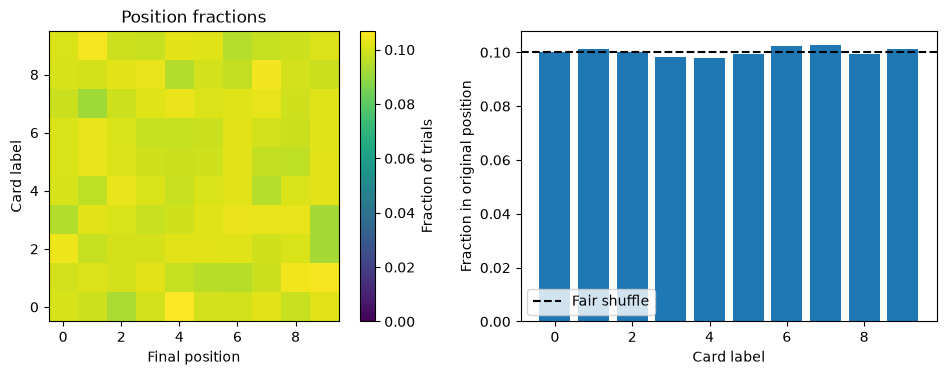

In [26]:
# Run after completing the counting loop.
fractions = counts / n_trials
same_position = np.diag(fractions)
print("Fraction in original position, for each card:")
print(np.round(same_position, 4))
print(f"Mean unchanged fraction: {same_position.mean():.4f}")
print(f"Expected fraction: {1 / n_cards:.4f}")
print(f"Mean number of unchanged cards: {same_position.sum():.4f}; expected: 1")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
image = axes[0].imshow(fractions, origin="lower", vmin=0)
axes[0].set(xlabel="Final position", ylabel="Card label", title="Position fractions")
fig.colorbar(image, ax=axes[0], label="Fraction of trials")
axes[1].bar(cards, same_position)
axes[1].axhline(1 / n_cards, color="black", linestyle="--", label="Fair shuffle")
axes[1].set(xlabel="Card label", ylabel="Fraction in original position")
axes[1].legend()
plt.tight_layout()
plt.show()

### Task 3 — Select an element with weights (optional)

Given nonnegative weights $w_i$ with a positive total, select index $i$ with probability

$$P(i)=\frac{w_i}{\sum_j w_j}.$$

Draw `r = rng.uniform(0, sum(weights))`. Starting at the first weight, subtract each weight from `r`. Return the first index for which `r < 0`. A weight of zero must never be selected.

1. Implement `weighted_index` using a loop.
2. Repeat the selection 10000 times for `[1, 2, 3, 4]`.
3. Compare the observed fractions with `[0.1, 0.2, 0.3, 0.4]` using a bar plot.

Assume the inputs are a nonempty list of nonnegative numbers with positive sum.

observed: [0.1036 0.2075 0.2957 0.3932]
expected: [0.1, 0.2, 0.3, 0.4]


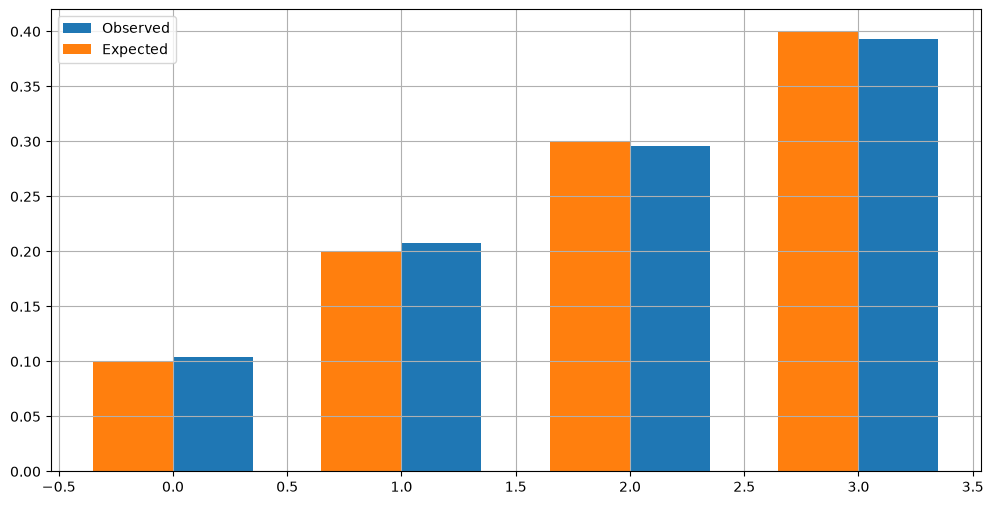

In [49]:
def weighted_index(weights, rng):
    # Work Here!
    r = rng.uniform(0, sum(weights))
    for i, w in enumerate(weights):
        r -= w
        if r < 0:
            return i

weights = [1, 2, 3, 4]
ntrials = 10000
counts = np.zeros(len(weights), dtype=int)
expect = [0.1, 0.2, 0.3, 0.4]

for k in range(ntrials):
    idx = weighted_index(weights, rng)
    counts[idx] += 1

observed = counts / ntrials


print("observed:", observed)
print("expected:", expect)

x = np.arange(len(weights))
width = 0.35

plt.figure(figsize=(12,6))
plt.bar(x+width/2, observed, width, label = "Observed")
plt.bar(x-width/2, expect, width, label = "Expected")
plt.grid()
plt.legend()
plt.show()



# Add your repetition, comparison and plot here.

### Task 4 — Build a generator and investigate RANDU

#### 4a. Multiplicative congruential algorithm

A **multiplicative congruential generator (MCG)** updates an integer state using

$$s_{n+1}=(a s_n)\bmod m,\qquad u_n=\frac{s_{n+1}}{m}.$$

Here `a` is the multiplier, `m` is the modulus, and `seed` is the starting state $s_0$. The modulo operation `%` keeps the state between `0` and `m - 1`. Dividing by `m` gives a number in $[0,1)$.

Complete the function below: update the state, then store `state / m` at each step. Return `n` values, **excluding the unmodified seed**. Keep the state and parameters as Python integers, and convert to floating point only when storing the normalized output.

For **RANDU**, use

$$a=65539=2^{16}+3,\qquad m=2^{31},\qquad s_0=1.$$

Use `2**31` in Python. A zero seed stays zero forever in a multiplicative generator. We use an odd seed for RANDU.

In [45]:
def mcg(n, seed, a, m):
    state = int(seed)
    a, m = int(a), int(m)
    values = np.empty(n)
    # Work Here!

    for i in range(n):
        state = (a * state) % m
        values[i] = state / m
        
    return values

In [46]:
# Small example you can check by hand:
# 1 -> 3 -> 9 -> 5 -> 4 -> 1, using a=3 and m=11.
small = mcg(5, seed=1, a=3, m=11)
assert np.allclose(small, np.array([3, 9, 5, 4, 1]) / 11)

randu_values = mcg(10000, seed=1, a=65539, m=2**31)
assert randu_values.shape == (10000,)
assert np.all((randu_values >= 0) & (randu_values < 1))
print("First five RANDU values:", randu_values[:5])
print("Same seed reproduces the sequence:",
      np.array_equal(randu_values, mcg(10000, 1, 65539, 2**31)))

First five RANDU values: [3.05189751e-05 1.83109660e-04 8.23987182e-04 3.29593616e-03
 1.23597323e-02]
Same seed reproduces the sequence: True


#### 4b. Marsaglia's planes: look at triples

A histogram only shows the distribution of individual values. A simulation may also need consecutive values to behave independently.

Form **overlapping consecutive triples**:

$$(u_0,u_1,u_2),\ (u_1,u_2,u_3),\ (u_2,u_3,u_4),\ldots$$

The helper below plots those triples in 3D and also shows a projection that reveals RANDU's planes. Compare RANDU with NumPy using the **same number of values**.

For RANDU, $a^2-6a+9=2^{32}$, which is divisible by $m=2^{31}$. Consequently,

$$u_{n+2}-6u_{n+1}+9u_n=k$$

for an integer $k$. The triples therefore lie on parallel planes. Plotting $9x-6y$ against $z$ makes these appear as lines $z=k-(9x-6y)$, even in a static notebook. This is a visual demonstration of the lattice structure; it is not a full implementation of the spectral test.

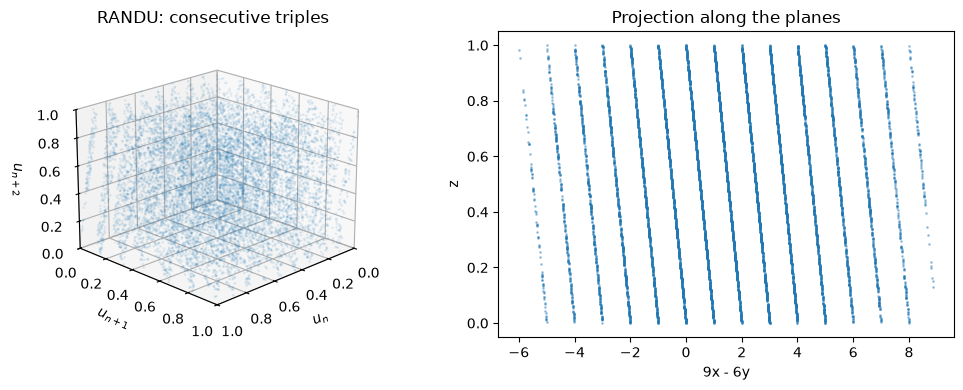

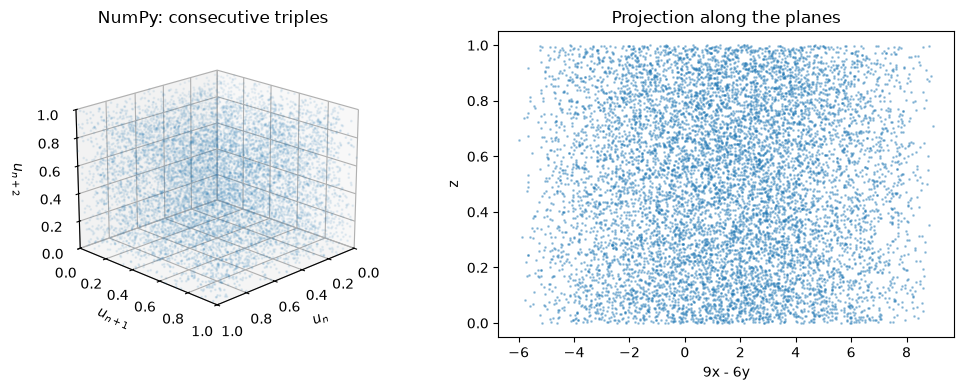

In [47]:
def plot_triples(values, title):
    x, y, z = values[:-2], values[1:-1], values[2:]
    fig = plt.figure(figsize=(10, 4))
    ax = fig.add_subplot(121, projection="3d")
    ax.scatter(x, y, z, s=1, alpha=0.35)
    ax.set(xlabel=r"$u_n$", ylabel=r"$u_{n+1}$", zlabel=r"$u_{n+2}$",
           xlim=(0, 1), ylim=(0, 1), zlim=(0, 1), title=title)
    ax.view_init(elev=20, azim=45)
    ax2 = fig.add_subplot(122)
    ax2.scatter(9 * x - 6 * y, z, s=1, alpha=0.35)
    ax2.set(xlabel="9x - 6y", ylabel="z", title="Projection along the planes")
    fig.tight_layout()
    plt.show()

numpy_values = rng.random(len(randu_values))
plot_triples(randu_values, "RANDU: consecutive triples")
plot_triples(numpy_values, "NumPy: consecutive triples")

#### 4c. Write checks of generator quality

Write a function `check_generator(values, name)` and apply it to RANDU and NumPy. You may ask AI to help write the function, but you must understand its output and check it against the formulas below.

Include these checks:

1. **Uniformity:** plot a density histogram on $[0,1]$ with a horizontal line at $1$. Print the sample mean and variance; the uniform targets are $1/2$ and $1/12$.
2. **Serial correlation:** compute the Pearson correlation of `values[:-1]` and `values[1:]`, for example with `np.corrcoef(...)[0, 1]`. A value near zero is consistent with no linear correlation, but does not establish independence.
3. **RANDU plane check:** calculate
   $$q_n=u_{n+2}-6u_{n+1}+9u_n,\qquad d_n=|q_n-\mathrm{round}(q_n)|.$$
   Print the fraction of triples with $d_n<10^{-10}$. Use `np.rint` for rounding. Compare the two generators. This check is specifically aimed at RANDU's defect, rather than being a universal test of randomness.

Before trusting the checks, try `np.full(10000, 0.5)` and `np.tile([0.25, 0.75], 5000)`. They have obvious defects. The correlation of a constant sequence is undefined: detect zero variance and print a clear message instead of a misleading number.

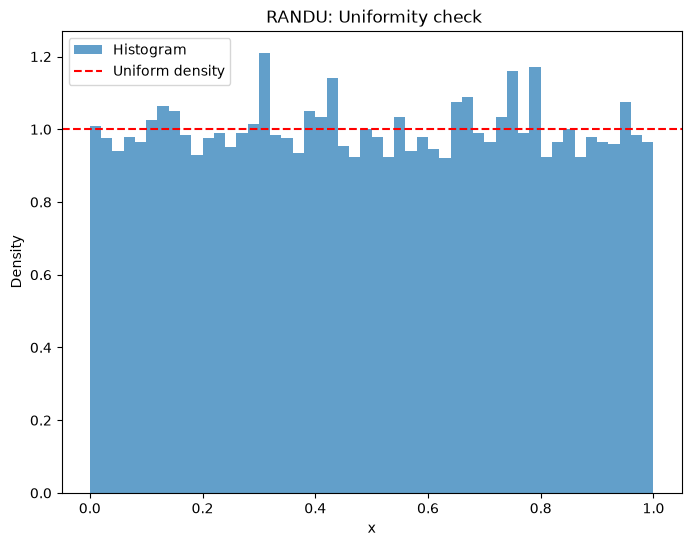

Serial correlation = 1.328208e-02
Fraction with d < 1e-10 = 1.000000


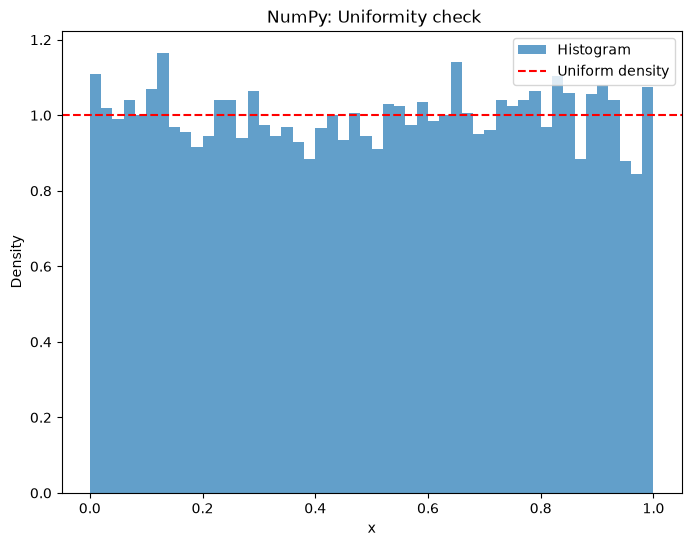

Serial correlation = -7.172544e-03
Fraction with d < 1e-10 = 0.000000


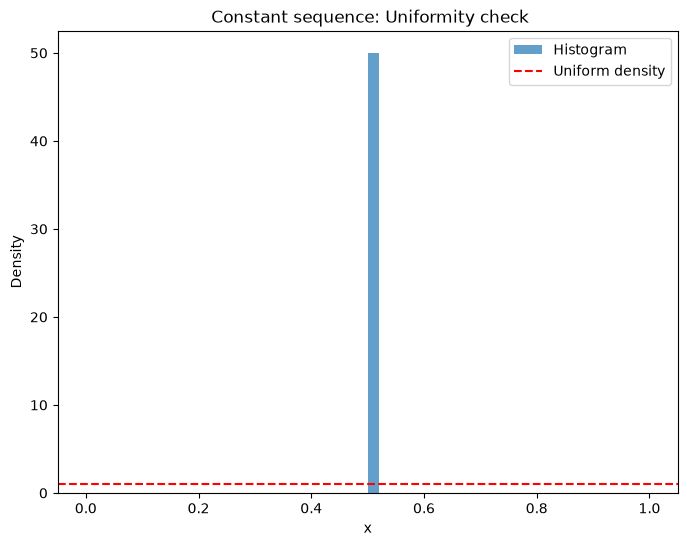

Serial correlation: undefined (zero variance)
Fraction with d < 1e-10 = 1.000000


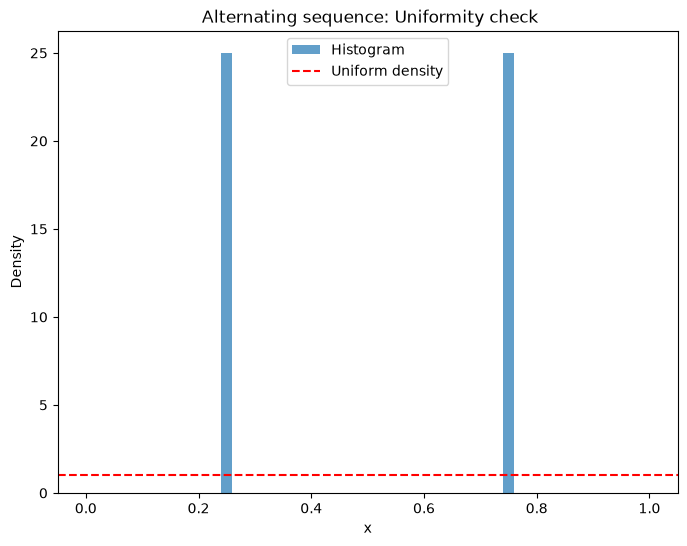

Serial correlation = -1.000000e+00
Fraction with d < 1e-10 = 1.000000


In [51]:
def check_generator(values, name):
    # Work Here! Write the calculations and the histogram.
    mean = np.mean(values)
    var = np.var(values)
    plt.figure(figsize=(8, 6))
    plt.hist(values, bins=50, range=(0,1), density=(True), alpha=0.7, label = "Histogram")
    plt.axhline(1, color = "red", linestyle = '--', label = 'Uniform density')
    plt.title(f" {name}: Uniformity check")
    plt.xlabel("x")
    plt.ylabel("Density")
    plt.legend()
    plt.show()

    if np.var(values[:-1]) == 0 or np.var(values[1:]) == 0:
        print("Serial correlation: undefined (zero variance)")
    else:
        corr = np.corrcoef(values[:-1], values[1:])[0,1]
        print(f"Serial correlation = {corr:.6e}")

    if len(values) < 3:
        print("RANDU plane check: not enough values")
        return


    q = values[2:] -6 *values[1:-1] + 9* values[:-2]
    d = np.abs(q-np.rint(q))

    fraction = np.mean(d < 1e-10)
    print(f"Fraction with d < 1e-10 = {fraction:.6f}")

check_generator(randu_values, "RANDU")
check_generator(numpy_values, "NumPy")
check_generator(np.full(10000, 0.5), "Constant sequence")
check_generator(np.tile([0.25, 0.75], 5000), "Alternating sequence")

#### 4d. Play with your own parameters

Choose your own `a`, `m`, and nonzero `seed` below. Generate a sequence, run your checks, and inspect its triples. Try a small modulus first so that repetitions are easy to see; then try larger values. Keep the seed between `1` and `m - 1`.

Change **one parameter at a time** and record at least two experiments. A different set of parameters may avoid the particular RANDU plane relation while still having other defects.

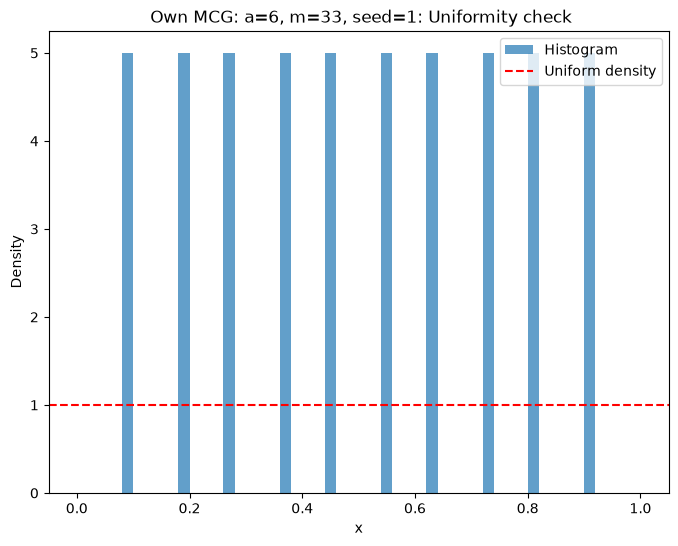

Serial correlation = 3.332990e-01
Fraction with d < 1e-10 = 0.000000


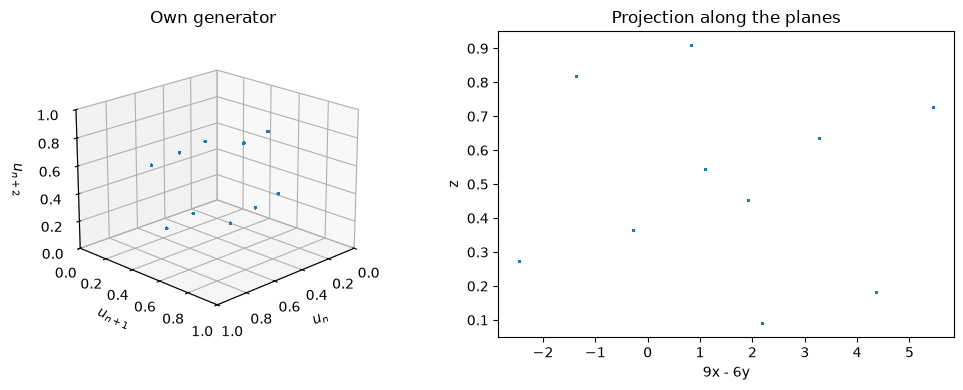

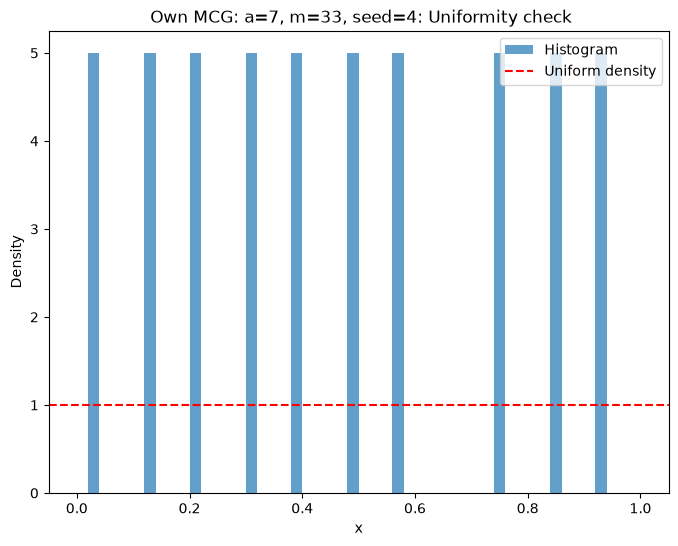

Serial correlation = 1.668432e-01
Fraction with d < 1e-10 = 0.000000


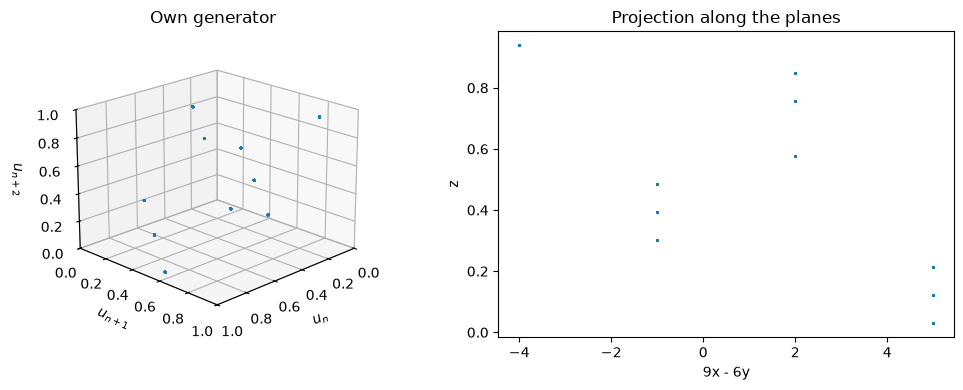

In [62]:
a_own = 6
m_own = 33
seed_own = 1

own_values = mcg(10000, seed_own, a_own, m_own)
check_generator(own_values, f"Own MCG: a={a_own}, m={m_own}, seed={seed_own}")
plot_triples(own_values, "Own generator")

a_own = 7
m_own = 33
seed_own = 4

own_values = mcg(10000, seed_own, a_own, m_own)
check_generator(own_values, f"Own MCG: a={a_own}, m={m_own}, seed={seed_own}")
plot_triples(own_values, "Own generator")

### Task 5 — Successive seeds (optional)

Investigate what happens if you start a **new RANDU sequence for each successive seed**, instead of drawing many values from one sequence.

1. For seeds `1, 2, ..., 1000`, generate **one** value with `mcg(1, seed, 65539, 2**31)`.
2. Plot seed versus the first value. Put these 1000 values into a `25 × 40` array and display it with `plt.imshow(..., vmin=0, vmax=1, aspect="auto")`.
3. Repeat for the **tenth** value from each seed, using `mcg(10, ...)[-1]`.
4. Compare these images with 1000 consecutive values from **one** RANDU sequence, reshaped in the same way.

For the first 1000 seeds, `65539 * seed < 2**31`, so the first outputs increase linearly with the seed: no modulo wrap has occurred yet. Does using a different seed for every value guarantee independent outputs?

In [ ]:
# Work Here! Generate the arrays and make the plots for the seed experiment.